# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


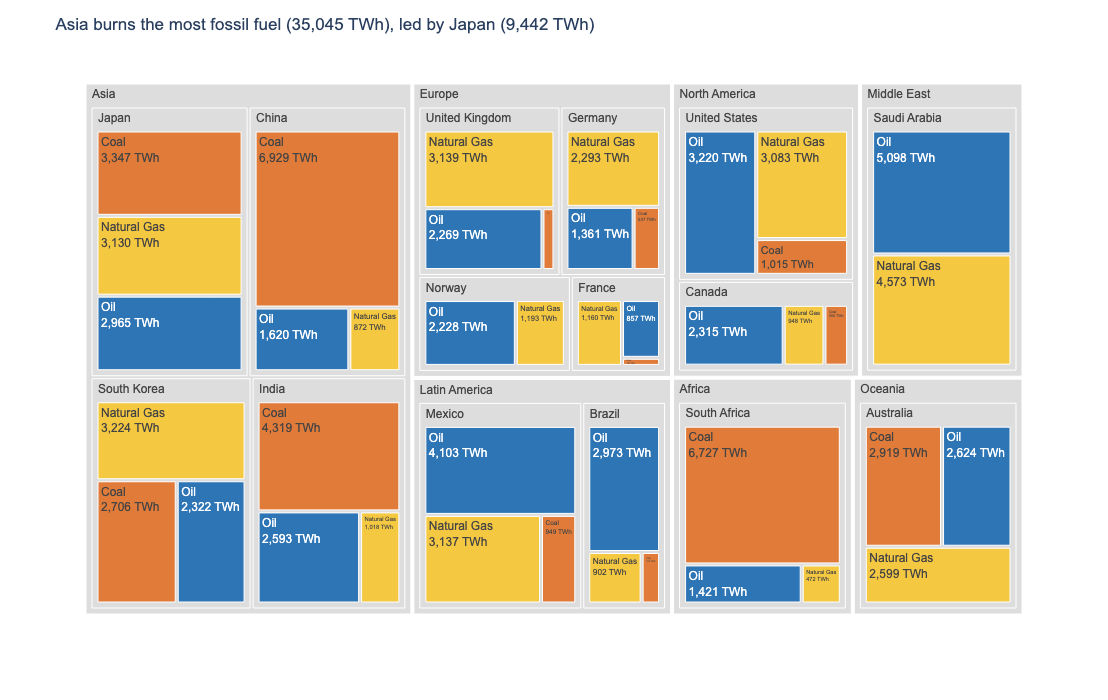

In [2]:
# Task 1
# YOUR CODE HERE
# Keep fossil rows only (Coal, Oil, Natural Gas); .copy() = independent table
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# One colour per fossil source, from the CVD-safe course palette (blue / orange / yellow)
fossil_colours = {'Coal': '#E07B39',          
                  'Oil': '#2E75B6',           
                  'Natural Gas': '#F5C842'}   

fig1 = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],     
    values='TWh',                             
    color='Source',                           
    color_discrete_map=fossil_colours,        
    labels={'TWh': 'Energy (TWh)', 'Source': 'Fossil source'},
    height=700, width=1100,
    template='plotly_white',
)

fig1.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',                 
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
)

# Grey out parent nodes (Region and Country): any colour that is not one of our three
fig1.data[0].marker.colors = [c if c in fossil_colours.values() else '#DDDDDD'
                              for c in fig1.data[0].marker.colors]

# Insight title: biggest region, and the biggest country inside it
region_twh = df_fossil.groupby('Region')['TWh'].sum()               
top_region = region_twh.idxmax()                                    
country_twh = df_fossil.loc[df_fossil['Region'] == top_region].groupby('Country')['TWh'].sum()
top_country = country_twh.idxmax()                                  

fig1.update_layout(
    title=(f'{top_region} burns the most fossil fuel ({region_twh[top_region]:,.0f} TWh), '
           f'led by {top_country} ({country_twh[top_country]:,.0f} TWh)'),
    font=dict(family='Arial', size=12),
)
fig1.show()

## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

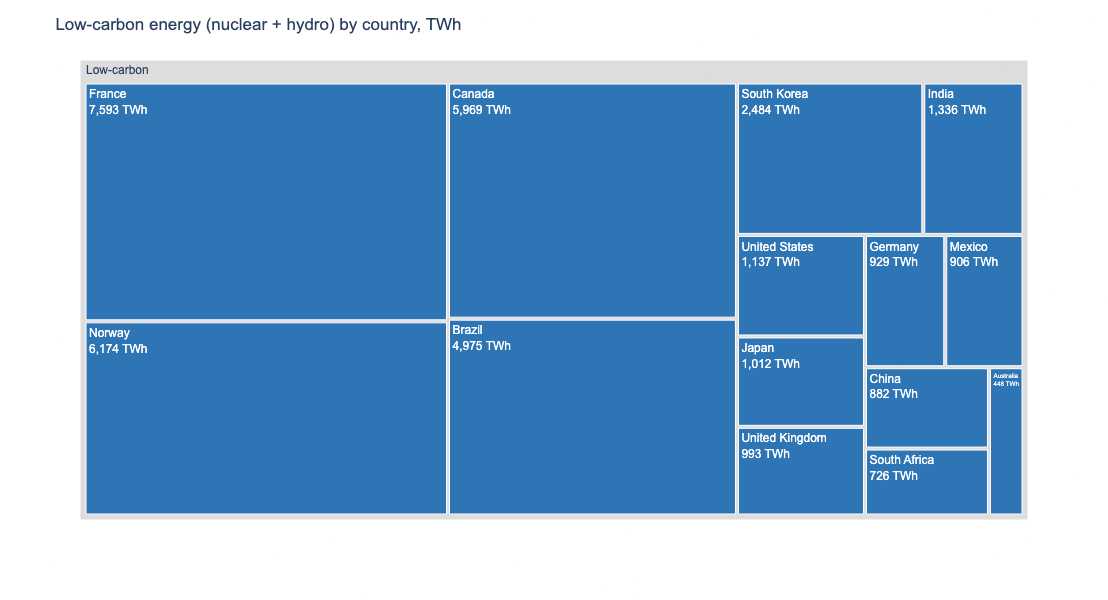

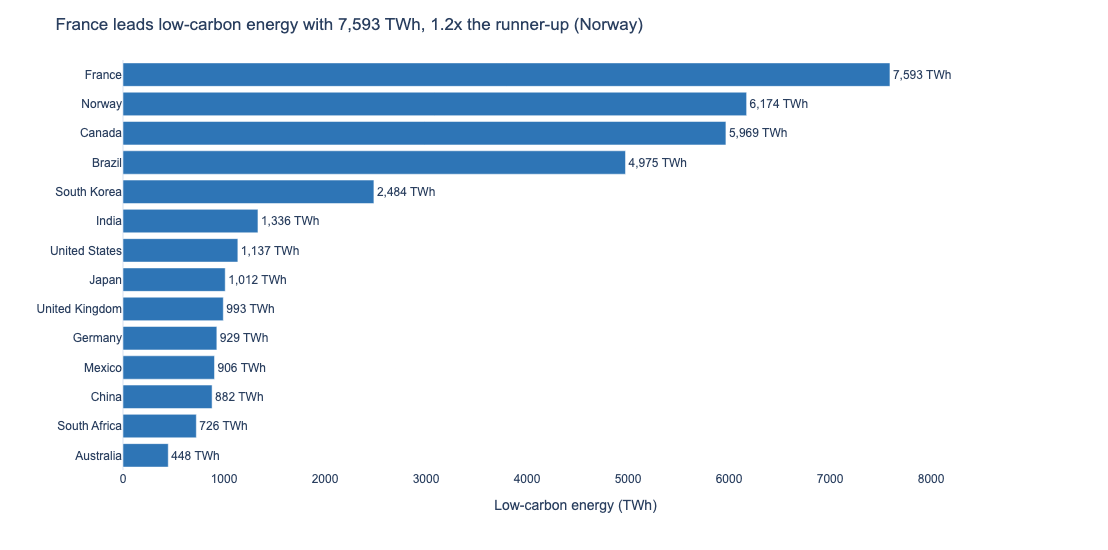

In [3]:
# Task 2 — charts
lc = (df.loc[df['Source_Type'] == 'Low-carbon']      
        .groupby('Country', as_index=False)['TWh'].sum())   
lc['All'] = 'Low-carbon'                             

fig2a = px.treemap(
    lc, path=['All', 'Country'], values='TWh',       
    color='All', color_discrete_map={'Low-carbon': '#2E75B6'},   
    labels={'TWh': 'Energy (TWh)'},
    height=600, width=1000, template='plotly_white',
)
fig2a.update_traces(
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh<extra></extra>',
)
# Grey out the dummy root node (the 'Low-carbon' parent); the country boxes stay blue
fig2a.data[0].marker.colors = ['#DDDDDD' if lbl == 'Low-carbon' else '#2E75B6'
                               for lbl in fig2a.data[0].labels]
fig2a.update_layout(title='Low-carbon energy (nuclear + hydro) by country, TWh',
                    font=dict(family='Arial', size=12))
fig2a.show()

# ---- Horizontal bar ----
lc_sorted = lc.sort_values('TWh', ascending=False)   
order = lc_sorted['Country'].tolist()                
leader, runner_up = order[0], order[1]
ratio = lc_sorted['TWh'].iloc[0] / lc_sorted['TWh'].iloc[1]

fig2b = px.bar(
    lc_sorted, x='TWh', y='Country', orientation='h',
    text='TWh',                                      
    category_orders={'Country': order},              
    color_discrete_sequence=['#2E75B6'],             
    labels={'TWh': 'Low-carbon energy (TWh)', 'Country': ''},
    height=550, template='plotly_white',
)
fig2b.update_traces(texttemplate='%{x:,.0f} TWh', textposition='outside')   
fig2b.update_layout(
    title=f'{leader} leads low-carbon energy with {lc_sorted["TWh"].iloc[0]:,.0f} TWh, '
          f'{ratio:.1f}x the runner-up ({runner_up})',
    font=dict(family='Arial', size=12),
    xaxis=dict(showgrid=False, range=[0, lc_sorted['TWh'].max() * 1.18]),   
)
fig2b.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

*The bar chart tells the ranking story more clearly. All bars share one baseline, so I compare lengths, and the human eye judges length far more accurately than area. Sorting puts the order in plain view, and the TWh labels give exact values. In the treemap, countries with similar totals have rectangles of different shapes, so it is hard to say which is bigger or by how much. With one level and no hierarchy, the treemap adds nothing that the bar chart does not show better.*

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

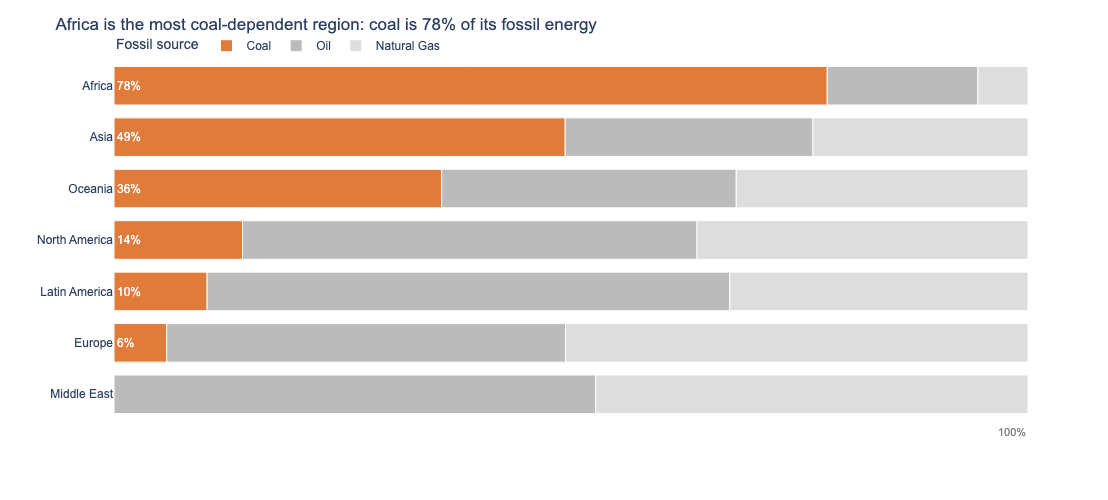

In [4]:
# Task 3
reg = df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()
reg['Share'] = reg['TWh'] / reg.groupby('Region')['TWh'].transform('sum')  

coal_share = (reg.pivot(index='Region', columns='Source', values='Share')
                 .fillna(0)['Coal'].sort_values(ascending=False))
region_order = coal_share.index.tolist()             

reg['Label'] = np.where(reg['Source'] == 'Coal', reg['Share'].map('{:.0%}'.format), '')

accent = {'Coal': fossil_colours['Coal'], 'Oil': '#BBBBBB', 'Natural Gas': '#DDDDDD'}

fig3 = px.bar(
    reg, x='Share', y='Region', color='Source', text='Label',
    color_discrete_map=accent,
    category_orders={'Region': region_order,
                     'Source': ['Coal', 'Oil', 'Natural Gas']},   
    labels={'Share': 'Share of fossil energy', 'Source': 'Fossil source'},
    height=500, width=1000, template='plotly_white',
)
fig3.update_traces(textposition='inside', insidetextanchor='start',   
                   textfont=dict(color='white', size=12),
                   marker_line_color='white', marker_line_width=1)    
top = region_order[0]
fig3.update_layout(
    title=f'{top} is the most coal-dependent region: coal is {coal_share[top]:.0%} of its fossil energy',
    font=dict(family='Arial', size=12),
    bargap=0.25,
    legend=dict(orientation='h', x=0, y=1.08),
    xaxis=dict(visible=False, range=[0, 1]),             
    yaxis=dict(title=''),
)
fig3.add_annotation(x=1, y=0, xref='x', yref='paper', xanchor='right', yanchor='top',
                    yshift=-4, text='100%', showarrow=False, font=dict(size=11, color='grey'))
fig3.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

*The treemap answers “where is the most fossil energy used in absolute terms, and which countries and sources make it up?”. It shows size and the Region, Country and Source nesting, which the stacked bar cannot, because every bar is the same length (100%). The stacked bar answers “which region relies most on coal as a share of its fossil energy?”. It lets me compare coal shares precisely along one baseline, which treemap areas cannot do.*